# Exploration: max_iter, quality gate, weight sensitivity and runtimes

Brief follow-up (README "Goal and success metrics"): re-select `max_iter` (622 was provisional, from the old 2-hour setup), check the 0.85 gate at the 17:00 cutoff, run the gate at weights 1.5, 2 and 3, and measure runtimes for the 18:00 to 18:30 batch.

Rules for this notebook:
- It is the "lab": it imports the pipeline from `src/` and never copies its logic.
- Choices are made on the **validation split** only. The **test split is scored once**, in section 7, for the configuration chosen automatically on validation.
- Nothing here changes `SETTINGS`; section 8 lists what the team must decide.

Run from VS Code with the `bike-demand` kernel; needs `data/raw/hour.csv`.

In [1]:
import copy
import logging
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "main.py").exists())
sys.path.insert(0, str(ROOT))

In [2]:
from src import main as pipeline
from src.clean_data import clean_dataframe
from src.evaluate import evaluate_model
from src.features import get_feature_preprocessor
from src.load_data import load_raw_data
from src.train import train_model

logging.disable(logging.WARNING)
SETTINGS = copy.deepcopy(pipeline.SETTINGS)
WEIGHTS = (1.5, 2.0, 3.0)
GATE = SETTINGS["quality_gate"]["threshold"]

## 1. Data and split, exactly as in `main`
Same cleaning (17:00 cutoff, training mode) and the same chronological split (validation and test 0.126 each).

In [3]:
t0 = time.perf_counter()
raw = load_raw_data(ROOT / SETTINGS["paths"]["raw_data"])
target = SETTINGS["problem"]["target_column"]
clean = clean_dataframe(raw, target_column=target, **SETTINGS["cleaning"])
load_clean_seconds = time.perf_counter() - t0


def split(df: pd.DataFrame) -> tuple:
    """Features/target and the time-ordered split from main, for a cleaned frame."""
    X, y = pipeline._features_and_target(df)
    return pipeline.split_data(X, y, **SETTINGS["split"])


X_train, X_val, X_test, y_train, y_val, y_test = split(clean)
for name, part in [("train", X_train), ("validation", X_val), ("test", X_test)]:
    ts = clean.loc[part.index, "ts"]
    print(f"{name:10s} {len(part):6d} rows  {ts.min():%Y-%m-%d} to {ts.max():%Y-%m-%d}  "
          f"mean demand {clean.loc[part.index, target].mean():6.1f}")

train       12980 rows  2011-01-09 to 2012-07-02  mean demand  168.0
validation   2186 rows  2012-07-02 to 2012-10-01  mean demand  289.3
test         2186 rows  2012-10-01 to 2012-12-31  mean demand  214.4


## 2. Helper: fit on train, score with the business metric
`evaluate_model` from `src/evaluate.py` computes `weighted_mae` and the ratio to same hour last week (`lag_168`) at a given under-forecast weight.

In [4]:
def fit(X_tr: pd.DataFrame, y_tr: pd.Series, features: dict, max_iter: int) -> tuple:
    """Train the brief's model with a given max_iter; return the pipeline and the fit time in seconds."""
    params = {**SETTINGS["model"], "max_iter": max_iter}
    start = time.perf_counter()
    model = train_model(X_tr, y_tr, get_feature_preprocessor(**features), "regression", params, 42)
    return model, time.perf_counter() - start


def score(model: object, X_eval: pd.DataFrame, y_eval: pd.Series, weight: float = 2.0) -> dict:
    """weighted_mae, under_share and the ratio to same hour last week at one under-forecast weight."""
    return evaluate_model(model, X_eval, y_eval, "regression", weight, "lag_168")

## 3. `max_iter` with the brief's features

In [5]:
BRIEF_FEATURES = SETTINGS["features"]
ITERATIONS = [25, 50, 100, 150, 200, 300, 400, 622]
rows = []
for it in ITERATIONS:
    model, seconds = fit(X_train, y_train, BRIEF_FEATURES, it)
    metrics = score(model, X_val, y_val)
    rows.append({"features": "brief", "max_iter": it, "val_ratio": metrics["weighted_mae_ratio"],
                 "under_share": metrics["under_share"], "fit_s": seconds})
brief_scan = pd.DataFrame(rows)
brief_scan.round(3)

,features,max_iter,val_ratio,under_share,fit_s
0,brief,25,1.692,0.477,0.465
1,brief,50,1.148,0.446,0.866
2,brief,100,1.053,0.527,1.685
3,brief,150,1.057,0.553,2.509
4,brief,200,1.086,0.593,3.298
5,brief,300,1.157,0.621,4.855
6,brief,400,1.214,0.636,6.438
7,brief,622,1.296,0.657,9.700


**Why the gate fails.** Mean hourly demand rises from the training period to the validation period (section 1). A tree model cannot forecast above the levels it has seen, so it under-forecasts most validation hours (`under_share` well above the 1/3 the 2/3 quantile aims for), and the 2x weight punishes exactly that. Same hour last week moves with the level for free. More iterations fit the old level more closely, so the ratio gets *worse* after about 100 iterations.

## 4. Candidate: two more cutoff-safe past-demand features (exploration only)
- `lag_24_before_cutoff`: demand at the same hour yesterday, **only for hours before 17:00** (later hours of D - 1 are after the cutoff, so missing)
- `last_hour_before_cutoff`: demand at 16:00 on D - 1, the most recent hour the 18:00 batch knows

They are built here from the cleaned calendar to test the idea. If the team adopts them, they move into `clean_data` with a leakage test, like the other three.

In [6]:
cutoff = SETTINGS["cleaning"]["cutoff_hour"]
demand_at = clean.set_index("ts")[target]
extended = clean.copy()
day = extended["ts"].dt.normalize()
yesterday_same_hour = extended["ts"] - pd.Timedelta(hours=24)
extended["lag_24_before_cutoff"] = yesterday_same_hour.map(demand_at).where(extended["hr"] < cutoff)
last_known = day - pd.Timedelta(days=1) + pd.Timedelta(hours=cutoff - 1)
extended["last_hour_before_cutoff"] = last_known.map(demand_at)

# Leakage check: every value used for date D comes from before cutoff_hour on D - 1
latest_allowed = day - pd.Timedelta(days=1) + pd.Timedelta(hours=cutoff)
assert (yesterday_same_hour[extended["hr"] < cutoff] < latest_allowed[extended["hr"] < cutoff]).all()
assert (last_known < latest_allowed).all()

EXTRA = ["lag_24_before_cutoff", "last_hour_before_cutoff"]
EXTENDED_FEATURES = {**BRIEF_FEATURES, "past_demand_columns": BRIEF_FEATURES["past_demand_columns"] + EXTRA}
Xe_train, Xe_val, Xe_test, ye_train, ye_val, ye_test = split(extended)
rows = []
for it in ITERATIONS:
    model, seconds = fit(Xe_train, ye_train, EXTENDED_FEATURES, it)
    metrics = score(model, Xe_val, ye_val)
    rows.append({"features": "brief + 2", "max_iter": it, "val_ratio": metrics["weighted_mae_ratio"],
                 "under_share": metrics["under_share"], "fit_s": seconds})
extended_scan = pd.DataFrame(rows)
extended_scan.round(3)

,features,max_iter,val_ratio,under_share,fit_s
0,brief + 2,25,1.678,0.474,0.432
1,brief + 2,50,1.104,0.412,0.852
2,brief + 2,100,0.966,0.455,1.693
3,brief + 2,150,0.940,0.469,2.505
4,brief + 2,200,0.934,0.479,3.298
5,brief + 2,300,0.922,0.486,4.883
6,brief + 2,400,0.920,0.495,6.749
7,brief + 2,622,0.930,0.515,9.960


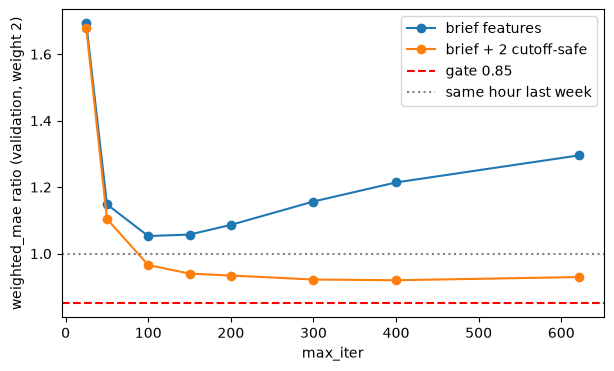

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
for label, scan in [("brief features", brief_scan), ("brief + 2 cutoff-safe", extended_scan)]:
    ax.plot(scan["max_iter"], scan["val_ratio"], marker="o", label=label)
ax.axhline(GATE, color="red", linestyle="--", label=f"gate {GATE}")
ax.axhline(1.0, color="grey", linestyle=":", label="same hour last week")
ax.set_xlabel("max_iter")
ax.set_ylabel("weighted_mae ratio (validation, weight 2)")
ax.legend()
plt.show()

## 5. Sensitivity: gate at weights 1.5, 2 and 3
Best `max_iter` per feature set, chosen on validation at weight 2.

In [8]:
best = {}
for label, scan, data, features in [
    ("brief", brief_scan, (X_train, y_train, X_val, y_val), BRIEF_FEATURES),
    ("brief + 2", extended_scan, (Xe_train, ye_train, Xe_val, ye_val), EXTENDED_FEATURES),
]:
    it = int(scan.loc[scan["val_ratio"].idxmin(), "max_iter"])
    model, _ = fit(data[0], data[1], features, it)
    best[label] = {"max_iter": it, "model": model, "features": features}
    ratios = {f"w{w}": score(model, data[2], data[3], w)["weighted_mae_ratio"] for w in WEIGHTS}
    print(f"{label:10s} max_iter {it:4d}  " + "  ".join(f"{k} {v:.3f}" for k, v in ratios.items()))

brief      max_iter  100  w1.5 1.033  w2.0 1.053  w3.0 1.077
brief + 2  max_iter  400  w1.5 0.915  w2.0 0.920  w3.0 0.926


## 6. Runtimes for the 18:00 batch

In [9]:
model = best["brief + 2"]["model"]
start = time.perf_counter()
model.predict(Xe_val.iloc[:24])
predict_seconds = time.perf_counter() - start
print(f"load + clean 17,379 raw rows: {load_clean_seconds:.2f} s")
print(f"fit at chosen max_iter: {extended_scan.loc[extended_scan['max_iter'] == best['brief + 2']['max_iter'], 'fit_s'].iloc[0]:.1f} s"
      f" (622 iterations: {extended_scan['fit_s'].iloc[-1]:.1f} s)")
print(f"predict 24 hours: {predict_seconds:.3f} s")

load + clean 17,379 raw rows: 0.02 s
fit at chosen max_iter: 6.7 s (622 iterations: 10.0 s)
predict 24 hours: 0.036 s


## 7. Test split, scored once
For the configuration with the lowest validation ratio across both feature sets (chosen in code, not by looking at test).

In [10]:
# Choose on validation only: the feature set whose best max_iter has the lowest validation ratio
best_val = {"brief": brief_scan["val_ratio"].min(), "brief + 2": extended_scan["val_ratio"].min()}
label = min(best_val, key=best_val.get)
X_eval, y_eval = (X_test, y_test) if label == "brief" else (Xe_test, ye_test)
test_metrics = score(best[label]["model"], X_eval, y_eval)
print(f"chosen on validation: {label}, max_iter {best[label]['max_iter']} (validation ratio {best_val[label]:.3f})")
print(f"TEST weighted_mae_ratio {test_metrics['weighted_mae_ratio']:.3f} (gate {GATE}), "
      f"weighted_mae {test_metrics['weighted_mae']:.1f} vs same hour last week {test_metrics['baseline_weighted_mae']:.1f}")

chosen on validation: brief + 2, max_iter 400 (validation ratio 0.920)
TEST weighted_mae_ratio 0.807 (gate 0.85), weighted_mae 84.9 vs same hour last week 105.3


## 8. Conclusions and recommendations for the team
Numbers from the run above (seed 42, validation July to September 2012, test October to December 2012).

| Question | Finding |
| --- | --- |
| `max_iter` with the brief's features | Best at **100** (validation ratio 1.053). 622 overfits the old demand level (1.296). |
| Gate at the 17:00 cutoff, brief's features | **Not met** at any `max_iter`: the model does not beat same hour last week on validation. |
| With 2 more cutoff-safe features | Validation ratio **0.920** at `max_iter` 400 (0.934 at 200): beats same hour last week, **still above 0.85**. |
| Weights 1.5 / 2 / 3 | 0.915 / 0.920 / 0.926 (brief + 2): the decision does not depend on the 2x assumption. |
| Test split, scored once | **0.807** for the configuration chosen on validation (weighted_mae 84.9 vs 105.3): below 0.85 on test, but the gate is defined on validation. |
| Runtimes | Load and clean well under 1 s, fit 6.5 s at 400 iterations (9.9 s at 622), forecast for 24 hours well under 1 s: far inside 18:00 to 18:30. |

**Root cause:** demand level rises from training (168 per hour) to validation (289); trees cannot extrapolate the level, so the model under-forecasts in summer 2012.

**Recommendations (team decisions, not changed here):**
1. Set `max_iter` from this notebook: 100 with the current features, or 400 if recommendation 2 is adopted.
2. Add `lag_24_before_cutoff` and `last_hour_before_cutoff` to `clean_data` (with a leakage test) and to `SETTINGS['features']`; this is a brief change.
3. Keep the gate at 0.85 and report honestly: with today's design the gate is **not met** on validation. Next ideas to test: a level-relative target (tried briefly, about 1.0, not better), retraining on the most recent months, or a shorter validation window.
4. The fallback stays a README gap until the gate is met.